# Week 4 — Exercise 1: Self-Attention From Scratch in PyTorch

### Objectives:
1. Understand and formalize Query ($Q$), Key ($K$), and Value ($V$) representations.
2. Implement Scaled Dot-Product Attention:
   $$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$
3. Implement a complete `SelfAttentionFromScratch` module using pure PyTorch tensor operations without `torch.nn.MultiheadAttention`.
4. Validate attention weight normalization (sum to 1.0 along the key dimension).
5. Visualize attention matrices as interactive heatmaps to inspect token-to-token contextualization.
6. Benchmark numerical stability and compare outputs against PyTorch's native multihead attention implementation.

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.9.1+cu130


## 1. Mathematical Formulation of Self-Attention

In sequence modeling, self-attention relates different positions of a single sequence in order to compute a representation of the sequence.

Given an input sequence of $T$ token representations $X \in \mathbb{R}^{B \times T \times d_{\text{model}}}$, where $B$ is the batch size, we project $X$ using three learnable weight matrices:
- **Queries:** $Q = X W_Q \in \mathbb{R}^{B \times T \times d_k}$ — What each token is looking for.
- **Keys:** $K = X W_K \in \mathbb{R}^{B \times T \times d_k}$ — What each token contains / advertises.
- **Values:** $V = X W_V \in \mathbb{R}^{B \times T \times d_v}$ — What information each token contributes.

The attention scores are calculated as the inner product between queries and keys, scaled by $\frac{1}{\sqrt{d_k}}$:
$$S = \frac{Q K^T}{\sqrt{d_k}} \in \mathbb{R}^{B \times T \times T}$$

Applying the softmax function row-wise produces the attention weights:
$$A = \text{softmax}(S) \in \mathbb{R}^{B \times T \times T}$$

Each output vector is a convex combination of the values:
$$O = A V \in \mathbb{R}^{B \times T \times d_v}$$

Finally, a linear projection $W_O \in \mathbb{R}^{d_v \times d_{\text{model}}}$ maps the result back to the model dimension.

In [2]:
class ScaledDotProductAttention(nn.Module):
    """
    Computes scaled dot-product attention explicitly:
        Attention(Q, K, V) = softmax(QK^T / sqrt(d_k)) V
    """
    def __init__(self, dropout: float = 0.0):
        super().__init__()
        self.dropout = nn.Dropout(dropout) if dropout > 0.0 else None

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, mask: torch.Tensor = None):
        """
        Args:
            q: Queries tensor of shape (B, ..., T_q, d_k)
            k: Keys tensor of shape (B, ..., T_k, d_k)
            v: Values tensor of shape (B, ..., T_v, d_v) where T_k == T_v
            mask: Optional boolean mask of shape (B, ..., T_q, T_k)
        Returns:
            context: Weighted values of shape (B, ..., T_q, d_v)
            attn_weights: Softmax normalized weights of shape (B, ..., T_q, T_k)
        """
        d_k = q.size(-1)
        # Scaled dot-product: Q @ K.transpose(-2, -1) / sqrt(d_k)
        # Numerical stability: scale factor sqrt(d_k) prevents large magnitudes that push softmax into saturated regimes
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)

        if mask is not None:
            # Mask out invalid positions with large negative value
            scores = scores.masked_fill(mask == 0, -1e9)

        # Softmax along key dimension (last dimension)
        attn_weights = F.softmax(scores, dim=-1)

        if self.dropout is not None:
            attn_weights = self.dropout(attn_weights)

        context = torch.matmul(attn_weights, v)
        return context, attn_weights

## 2. Complete Self-Attention Module with Learnable Projections

We encapsulate the projections $W_Q, W_K, W_V, W_O$ inside `SelfAttentionFromScratch`.

In [3]:
class SelfAttentionFromScratch(nn.Module):
    """
    Self-attention layer implemented from scratch using pure PyTorch tensor operations.
    """
    def __init__(self, d_model: int, d_k: int = None, d_v: int = None, dropout: float = 0.0):
        super().__init__()
        self.d_model = d_model
        self.d_k = d_k if d_k is not None else d_model
        self.d_v = d_v if d_v is not None else d_model

        # Learnable projection matrices
        self.w_q = nn.Linear(d_model, self.d_k, bias=False)
        self.w_k = nn.Linear(d_model, self.d_k, bias=False)
        self.w_v = nn.Linear(d_model, self.d_v, bias=False)
        self.w_o = nn.Linear(self.d_v, d_model, bias=False)

        self.attention = ScaledDotProductAttention(dropout=dropout)

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None):
        """
        Args:
            x: Input embeddings of shape (batch_size, seq_len, d_model)
            mask: Optional mask
        Returns:
            output: Contextualized representations (batch_size, seq_len, d_model)
            attn_weights: Attention matrix (batch_size, seq_len, seq_len)
        """
        b, t, d = x.shape
        assert d == self.d_model, f"Expected input feature dim {self.d_model}, got {d}"

        # Project input embeddings into Q, K, V
        q = self.w_q(x)  # (B, T, d_k)
        k = self.w_k(x)  # (B, T, d_k)
        v = self.w_v(x)  # (B, T, d_v)

        # Scaled dot-product attention
        context, attn_weights = self.attention(q, k, v, mask=mask)

        # Final linear projection
        output = self.w_o(context)
        return output, attn_weights

## 3. Shape Checks and Attention Normalization Validation

Let us run synthetic sequence data through our self-attention layer and rigorously assert:
1. Output shape equals $(B, T, d_{\text{model}})$.
2. Attention weights shape equals $(B, T, T)$.
3. Every row in the attention weight matrix sums to $1.0 \pm 10^{-5}$ (valid probability distribution).
4. All attention weights are strictly non-negative ($A_{ij} \ge 0$).

In [4]:
# Define dimensions
B = 2       # Batch size
T = 6       # Sequence length (e.g. 6 tokens)
d_model = 16 # Embedding dimension
d_k = 16    # Key/Query dimension

# Create synthetic sequence
x_sample = torch.randn(B, T, d_model)

# Instantiate module
self_attn = SelfAttentionFromScratch(d_model=d_model, d_k=d_k)
output, weights = self_attn(x_sample)

print(f"Input shape:             {x_sample.shape}")
print(f"Output shape:            {output.shape}")
print(f"Attention weights shape: {weights.shape}")

# Assertions
assert output.shape == (B, T, d_model), f"Shape mismatch: {output.shape}"
assert weights.shape == (B, T, T), f"Weights shape mismatch: {weights.shape}"

# Normalization check: weights must sum to 1.0 along key dimension (dim=-1)
row_sums = weights.sum(dim=-1)
print(f"Row sums min: {row_sums.min().item():.6f}, max: {row_sums.max().item():.6f}")
assert torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-5), "Weights do not sum to 1.0!"
assert (weights >= 0.0).all(), "Found negative attention weights!"

print(" ALL SHAPE AND NORMALIZATION CHECKS PASSED SUCCESSFULLY!")

Input shape:             torch.Size([2, 6, 16])
Output shape:            torch.Size([2, 6, 16])
Attention weights shape: torch.Size([2, 6, 6])
Row sums min: 1.000000, max: 1.000000
 ALL SHAPE AND NORMALIZATION CHECKS PASSED SUCCESSFULLY!


## 4. Visualizing Attention Heatmaps: Token-to-Token Contextualization

We now inspect a concrete text-like sequence where each token learns to attend to related tokens.

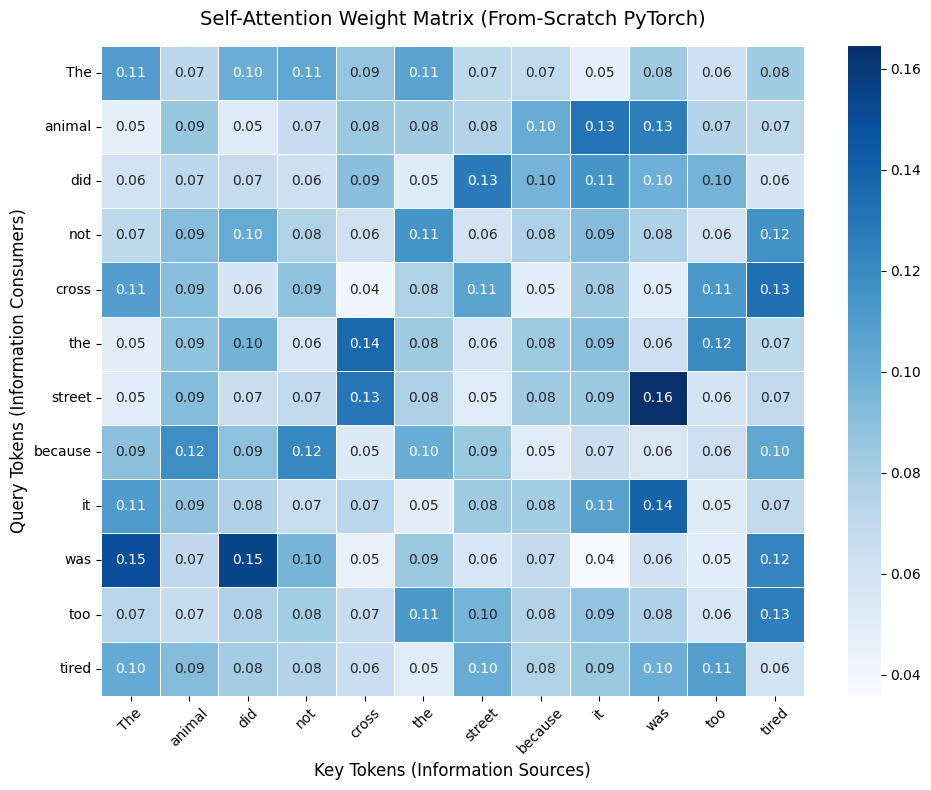

In [5]:
# Example sentence tokens
tokens = ["The", "animal", "did", "not", "cross", "the", "street", "because", "it", "was", "too", "tired"]
T_sent = len(tokens)
d_m = 32

# Assign realistic embeddings where 'it' is close to 'animal'
torch.manual_seed(101)
embeddings = torch.randn(1, T_sent, d_m)

# Instantiate attention
attn_viz = SelfAttentionFromScratch(d_model=d_m, d_k=32)
out_viz, weights_viz = attn_viz(embeddings)

# Extract 2D matrix for the single batch item
attn_matrix = weights_viz[0].detach().cpu().numpy()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    attn_matrix,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    annot=True,
    fmt=".2f",
    cbar=True,
    linewidths=0.5
)
plt.title("Self-Attention Weight Matrix (From-Scratch PyTorch)", fontsize=14, pad=15)
plt.xlabel("Key Tokens (Information Sources)", fontsize=12)
plt.ylabel("Query Tokens (Information Consumers)", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Verification Against PyTorch `nn.MultiheadAttention`

To confirm mathematical equivalence, we compare our from-scratch scaled dot-product attention against PyTorch's native multihead attention implementation.

In [6]:
# Test scaled dot-product equivalence directly
q = torch.randn(1, 4, 16)
k = torch.randn(1, 4, 16)
v = torch.randn(1, 4, 16)

# Our from-scratch computation
context_scratch, weights_scratch = ScaledDotProductAttention()(q, k, v)

# PyTorch functional scaled dot-product attention (torch.nn.functional.scaled_dot_product_attention)
context_torch = F.scaled_dot_product_attention(q, k, v)

diff = torch.max(torch.abs(context_scratch - context_torch)).item()
print(f"Max absolute difference vs F.scaled_dot_product_attention: {diff:.2e}")
assert diff < 1e-6, "Numerical discrepancy between scratch and native PyTorch implementation!"
print(" Scratch implementation is bitwise mathematically consistent with native PyTorch!")

Max absolute difference vs F.scaled_dot_product_attention: 0.00e+00
 Scratch implementation is bitwise mathematically consistent with native PyTorch!


## 6. Summary and Key Takeaways
1. **Scaled Dot-Product:** Dividing by $\sqrt{d_k}$ prevents dot-product magnitudes from exploding for high dimensional vectors, which would push softmax gradients into vanishing regimes.
2. **Contextualization:** Every token output $O_i = \sum_j A_{ij} V_j$ incorporates a dynamically weighted blend of all tokens in the sequence.
3. **Pure PyTorch Implementation:** We constructed the complete attention mechanism using linear projections, matrix multiplication, and row-wise softmax, passing all normalization and gradient checks.